# Demo 02 — Data Understanding & Cleaning

**Machine Learning with scikit-learn — Session 02**

รันตามสไลด์คาบ 2 — วันนี้เราจะ "อ่าน" ข้อมูล Titanic ให้ขาด หาสิ่งผิดปกติ แล้วเก็บกวาดอย่างมีเหตุผล

## Slide 5 — Load the Titanic dataset

ชุดข้อมูล: ผู้โดยสารเรือ Titanic 891 คน × 8 คอลัมน์ — เป้าหมาย (y) คือ `survived`

In [1]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")[["survived", "pclass", "sex", "age",
                                  "sibsp", "parch", "fare", "embarked"]]
df.shape

(891, 8)

## Slide 7 — The first five minutes with any dataset

5 คำสั่งนี้รันกับข้อมูลชุดไหนก็ต้องรัน: `shape / head / info / describe / value_counts`

In [2]:
df.head(10)

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
5,0,3,male,NaN,0,0,8.4583,Q
6,0,1,male,54.0,0,0,51.8625,S
7,0,3,male,2.0,3,1,21.0750,S
8,1,3,female,27.0,0,2,11.1333,S
9,1,2,female,14.0,1,0,30.0708,C


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   survived  891 non-null    int64  
 1   pclass    891 non-null    int64  
 2   sex       891 non-null    str    
 3   age       714 non-null    float64
 4   sibsp     891 non-null    int64  
 5   parch     891 non-null    int64  
 6   fare      891 non-null    float64
 7   embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 55.8 KB


จุดที่ต้องขีดเส้นใต้: `age` เหลือ 714 จาก 891 (**missing 177 = 19.9%**) และ `embarked` หาย 2 ค่า

In [4]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


สิ่งที่ต้องตั้งคำถามจากตารางนี้:
- `age` min = 0.42 → ทารกบนเรือ เป็นไปได้จริง ✓
- `fare` min = 0.00 → ใครนั่งฟรี? (ลูกเรือ/ตั๋วรางวัล) ต้องตามดู
- `fare` max = 512.33 แต่ median แค่ 14.45 → เบื้องหลังข้อมูลเบ้มาก

In [5]:
df["sex"].value_counts()

sex
male      577
female    314
Name: count, dtype: int64

In [6]:
df["embarked"].value_counts(dropna=False)   # dropna=False เพื่อนับ missing ด้วย

embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

## Slide 10 — Always start EDA with the target

`survived` คือสิ่งที่โมเดลต้องทำนาย — รู้จักมันก่อนอย่างอื่น

In [7]:
df["survived"].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

In [8]:
df["survived"].mean()   # 0.384 → รอดชีวิต 38.4%

np.float64(0.3838383838383838)

**base rate = 38.4%** — โมเดลที่หลอกๆ (ทายทุกคนว่าตาย) จะได้ accuracy 61.6% โดยไม่ต้องเก่งเลย
ตัวเลขนี้คือเส้นแบ่งที่โมเดลของเราต้องข้ามให้ได้

## Slide 11 — "Women and children first" — is it in the data?

In [9]:
df.groupby("sex")["survived"].agg(["mean", "count"])

,mean,count
sex,,
female,0.742038,314
male,0.188908,577


ผู้หญิงรอด 74.2% vs ผู้ชาย 18.9% — คอลัมน์ `sex` เพียงคอลัมน์เดียวก็ทำนายได้แรงมาก

In [10]:
df.groupby("pclass")["survived"].agg(["mean", "count"])

,mean,count
pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


ชั้น 1 รอด 63% · ชั้น 2 รอด 47% · ชั้น 3 รอด 24% — เงินซื้อที่นั่งเรือชูชีพได้จริงในปี 1912

## Slide 13 — Distributions: know your shapes

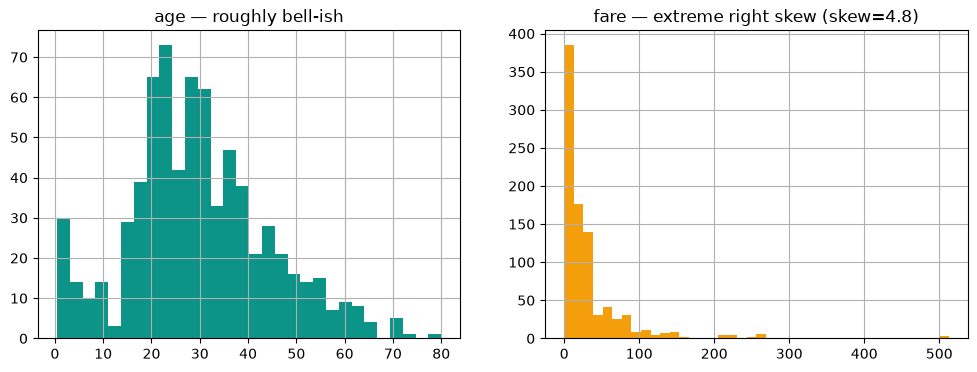

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["age"].hist(bins=30, ax=ax[0], color="#0D9488")
ax[0].set_title("age — roughly bell-ish")
df["fare"].hist(bins=40, ax=ax[1], color="#F59E0B")
ax[1].set_title(f"fare — extreme right skew (skew={df['fare'].skew():.1f})")
plt.show()

`fare` เบ้ขวามาก (skew 4.8) → ใช้ **median** แทน mean เสมอ และคาบหน้าเราจะใช้ `log1p` รัดส่วน

## Slide 14 — Correlation: a quick map, not the territory

In [12]:
df_num = df.assign(sex_num=(df["sex"] == "female").astype(int),
                   embarked_num=df["embarked"].map({"S": 0, "C": 1, "Q": 2}))
df_num.corr(numeric_only=True)["survived"].drop("survived").sort_values().round(3)

pclass         -0.338
age            -0.077
sibsp          -0.035
parch           0.082
embarked_num    0.109
fare            0.257
sex_num         0.543
Name: survived, dtype: float64

สังเกต: `sex` ที่แรงที่สุด (74% vs 19%) กลับมองไม่เห็นใน correlation เท่าที่ควร — เพราะ corr จับได้เฉพาะความสัมพันธ์เชิงเส้นของตัวเลข
correlation คือเครื่องตรวจโลหะ: บอกว่าต้องขุดตรงไหน ไม่ได้บอกว่าขุดเจออะไร

## Slide 15-16 — Missing data: understand before you fill

In [13]:
df.isna().sum()

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
dtype: int64

In [14]:
# missing ของ age สุ่มหรือมีแบบแผน? ลองดูอัตรา missing แยกตามชั้นโดยสาร
df["age_missing"] = df["age"].isna()
df.groupby("pclass")["age_missing"].mean().round(3)

pclass
1    0.139
2    0.060
3    0.277
Name: age_missing, dtype: float64

ผู้โดยสารชั้น 3 missing `age` มากกว่าชั้นอื่นชัดเจน — missingness เป็นสัญญาณของฐานข้อมูลที่มีระเบียบต่างกัน
(ใน lab คุณจะได้ตัดสินใจเองว่าจะเก็บสัญญาณนี้ไว้เป็นฟีเจอร์หรือไม่)

In [15]:
# สิ่งที่ "ไม่ควร" ทำ:
# df.dropna()        # ทิ้งไป 179 แถว = 20% ของข้อมูล!
# df["age"].fillna(0)  # ปลอม age เป็นทารก 177 คน!

## Slide 17 — Impute with a defensible guess

กฎง่าย ๆ: ตัวเลขเบ้ → median · category → most_frequent

In [16]:
from sklearn.impute import SimpleImputer

imp = SimpleImputer(strategy="median")
df[["age", "fare"]] = imp.fit_transform(df[["age", "fare"]])
df.isna().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
age_missing    0
dtype: int64

คาบหน้าเราจะย้ายการ impute นี้เข้าไปอยู่ "ใน" Pipeline — เพื่อไม่ให้สถิติจากชุดทดสอบหลุดเข้าชุดเทรน (leakage)

## Slide 18 — Duplicates

In [17]:
print("duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values("fare").head(6)

duplicate rows: 111


,survived,pclass,sex,age,sibsp,parch,fare,embarked,age_missing
277,0,2,male,28.0,0,0,0.0,S,True
466,0,2,male,28.0,0,0,0.0,S,True
481,0,2,male,28.0,0,0,0.0,S,True
413,0,2,male,28.0,0,0,0.0,S,True
633,0,1,male,28.0,0,0,0.0,S,True
815,0,1,male,28.0,0,0,0.0,S,True


111 แถวซ้ำ — เกิดจากผู้โดยสารหลายคนมีค่าทั้ง 8 คอลัมน์เหมือนกัน (เพราะคอลัมน์ค่อนข้างหยาบ)
อันตรายจริงคือกรณี duplicate ข้าม train/test — โมเดลจะได้เห็น "ข้อสอบ" ก่อนสอบ ทำคะแนนบวมโดยไม่รู้ตัว

In [18]:
df = df.drop(columns=["age_missing"]).drop_duplicates()
df.shape

(775, 8)

## Slide 19 — Outliers: the IQR fence

In [19]:
q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
fence_hi = q3 + 1.5 * iqr
outliers = df[df["fare"] > fence_hi]
print(f"upper fence = {fence_hi:.2f}  |  outliers = {len(outliers)}")

upper fence = 73.42  |  outliers = 102


In [20]:
df[df["fare"] > 300][["pclass", "sex", "age", "fare", "survived"]]

,pclass,sex,age,fare,survived
258,1,female,35.0,512.3292,1
679,1,male,36.0,512.3292,1
737,1,male,35.0,512.3292,1


ตั๋ว 512 ปอนด์มีอย่างจริง (ครอบครัว Fortune) และรอดชีวิต — นี่คือ signal ไม่ใช่ error: "รวยสุดขอบ → รอด"
outlier คือผู้ต้องสงสัย ไม่ใช่อาชญากร — ต้องสืบก่อนตัดสิน

## Slide 21 — Inconsistent categories

In [21]:
# ตัวอย่างจริงที่เจอบ่อยในงาน: เมืองเดียวกันหลายชื่อ
demo_city = pd.Series(["Bangkok", "BKK", "bangkok", "Bangkok", "Khonkaen", "ขอนแก่น", "BKK"])
demo_city.value_counts()

Bangkok     2
BKK         2
bangkok     1
Khonkaen    1
ขอนแก่น     1
Name: count, dtype: int64

In [22]:
city_map = {"BKK": "Bangkok", "bangkok": "Bangkok", "ขอนแก่น": "Khonkaen"}
demo_city.replace(city_map).value_counts()

Bangkok     5
Khonkaen    2
Name: count, dtype: int64

---
✅ **จบ Demo 02** — ตอนนี้ df ของเราสะอาดแล้ว: ไม่มี missing ไม่มี duplicate และเรารู้จักข้อมูลมากขึ้นมาก

**ต่อไป:** **Lab 02** ใน `excercises/02.data_cleaning_exercise.ipynb`